# Assumption Checks for Parametric Tests

Before applying **parametric statistical tests** (t-tests, ANOVA, regression), we must check their key assumptions. If they are badly violated, p-values and confidence intervals can be wrong.

In [1]:
# Notebook setup: wide, readable figures with an opaque white background.
# (Without the hook, base-R plots render with a transparent background and
#  the black axes/labels disappear on dark-themed notebook viewers.)
options(repr.plot.width = 10, repr.plot.height = 6, repr.plot.res = 100)
setHook("before.plot.new", function() par(bg = "white"))

## 1. Independence of Observations
- Each data point should be independent of the others:
$$
\text{Cov}(X_i, X_j) = 0 \quad \forall\, i \neq j
$$
- Mostly ensured by **study design** (random sampling, random assignment). Common violations: repeated measurements of the same person, students within the same class, measurements over time (autocorrelation).

## 2. Normality
- Residuals (or the data within each group) should be approximately normal: $X \sim \mathcal{N}(\mu, \sigma^2)$.
- **Shapiro–Wilk test**: $H_0$: the data come from a normal distribution.
- **Visual checks**: histogram and **Q–Q plot** (points should follow the diagonal line).

## 3. Homogeneity of Variances (Homoscedasticity)
$$
\sigma_1^2 = \sigma_2^2 = \dots = \sigma_k^2
$$
- **Levene's test** (robust to non-normality) and **Bartlett's test** (more powerful, but sensitive to non-normality).
- **Visual checks**: side-by-side boxplots, residuals-vs-fitted plots.

If these assumptions are violated:
- Use **transformations** (log, square root, Box–Cox).
- Use **robust alternatives** (Welch t-test / Welch ANOVA for unequal variances).
- Use **non-parametric tests** (Mann–Whitney, Kruskal–Wallis).

## 4. Checking Normality: Normal vs Skewed Data

In [2]:
set.seed(42)
data_norm   <- rnorm(40, mean = 5, sd = 1)
data_skewed <- rexp(40, rate = 0.5)

sw_norm <- shapiro.test(data_norm)
sw_skew <- shapiro.test(data_skewed)
sw_norm
sw_skew


	Shapiro-Wilk normality test

data:  data_norm
W = 0.97314, p-value = 0.4497



	Shapiro-Wilk normality test

data:  data_skewed
W = 0.52377, p-value = 3.27e-10


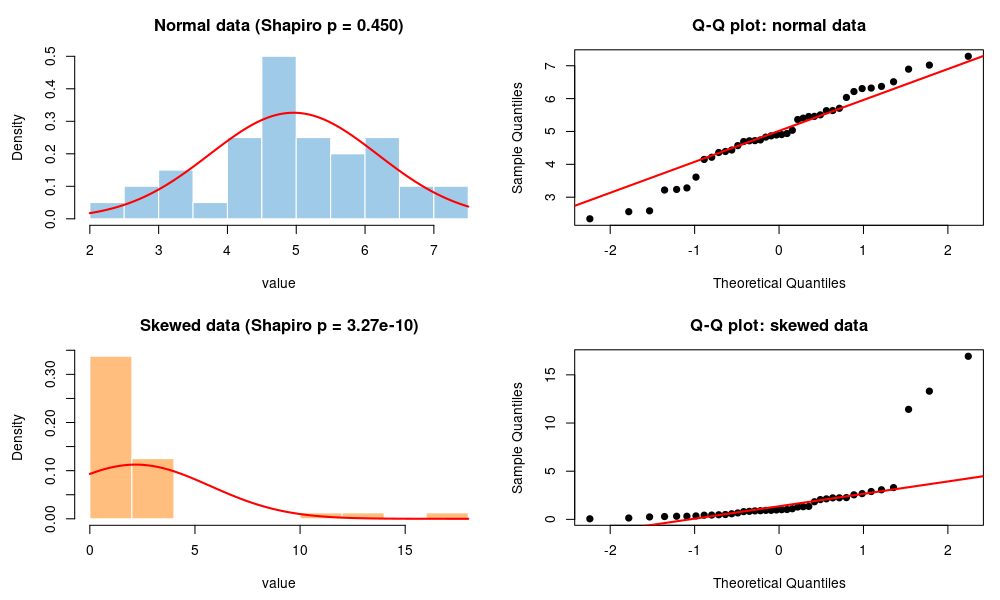

In [3]:
par(mfrow = c(2, 2), mar = c(4.5, 4.5, 3, 1))
hist(data_norm, breaks = 10, freq = FALSE, col = "#A0CBE8", border = "white",
     main = sprintf("Normal data (Shapiro p = %.3f)", sw_norm$p.value), xlab = "value")
curve(dnorm(x, mean(data_norm), sd(data_norm)), add = TRUE, col = "red", lwd = 2)
qqnorm(data_norm, pch = 19, main = "Q-Q plot: normal data"); qqline(data_norm, col = "red", lwd = 2)

hist(data_skewed, breaks = 10, freq = FALSE, col = "#FFBE7D", border = "white",
     main = paste0("Skewed data (Shapiro p = ", format.pval(sw_skew$p.value, digits = 3), ")"), xlab = "value")
curve(dnorm(x, mean(data_skewed), sd(data_skewed)), add = TRUE, col = "red", lwd = 2)
qqnorm(data_skewed, pch = 19, main = "Q-Q plot: skewed data"); qqline(data_skewed, col = "red", lwd = 2)

*Insight: In a Q–Q plot, right-skewed data curve **upward** at the right end: the largest observations are far bigger than a normal distribution would produce. Reading that shape tells you more than the p-value, and it tells you which fix to try (here, a log transform).*

## 5. Checking Homogeneity of Variances

Equal variances   - Levene p = 0.1605 | Bartlett p = 0.1253 


Unequal variances - Levene p = 0.00042 | Bartlett p = 1.44e-09 


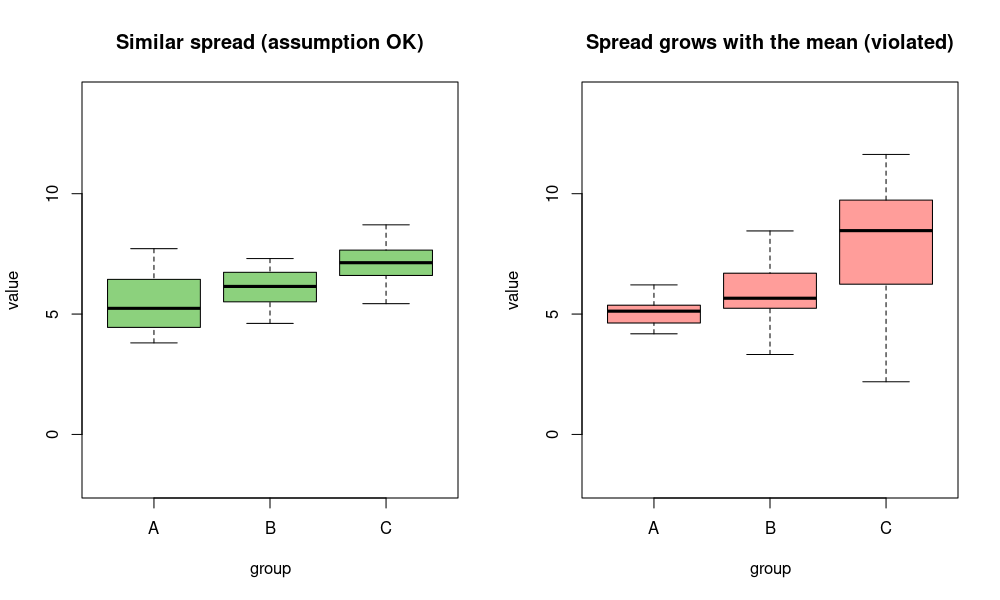

In [4]:
if (!requireNamespace("car", quietly = TRUE)) install.packages("car")
suppressPackageStartupMessages(library(car))

set.seed(7)
equal_var <- data.frame(value = c(rnorm(20, 5, 1), rnorm(20, 6, 1), rnorm(20, 7, 1)),
                        group = factor(rep(c("A", "B", "C"), each = 20)))
unequal_var <- data.frame(value = c(rnorm(20, 5, 0.5), rnorm(20, 6, 1.5), rnorm(20, 7, 3)),
                          group = factor(rep(c("A", "B", "C"), each = 20)))

cat("Equal variances   - Levene p =", round(leveneTest(value ~ group, equal_var)$`Pr(>F)`[1], 4),
    "| Bartlett p =", round(bartlett.test(value ~ group, equal_var)$p.value, 4), "\n")
cat("Unequal variances - Levene p =", signif(leveneTest(value ~ group, unequal_var)$`Pr(>F)`[1], 3),
    "| Bartlett p =", signif(bartlett.test(value ~ group, unequal_var)$p.value, 3), "\n")

par(mfrow = c(1, 2))
boxplot(value ~ group, equal_var, col = "#8CD17D", main = "Similar spread (assumption OK)", ylim = c(-2, 14))
boxplot(value ~ group, unequal_var, col = "#FF9D9A", main = "Spread grows with the mean (violated)", ylim = c(-2, 14))

In [5]:
leveneTest(value ~ group, data = unequal_var)

,Df,F value,Pr(>F)
,<int>,<dbl>,<dbl>
group,2,8.938922,0.0004201104
,57,NA,NA


## 6. Regression Diagnostics: Residual Plots

For regression and ANOVA, the assumptions are about the **residuals**. R's `plot()` on a fitted model draws four diagnostic plots:

1. **Residuals vs Fitted** – should be a shapeless cloud around 0 (checks linearity and equal variance)
2. **Normal Q–Q** – residuals should follow the line (checks normality)
3. **Scale–Location** – should be a flat band (checks equal variance)
4. **Residuals vs Leverage** – flags influential points (Cook's distance)

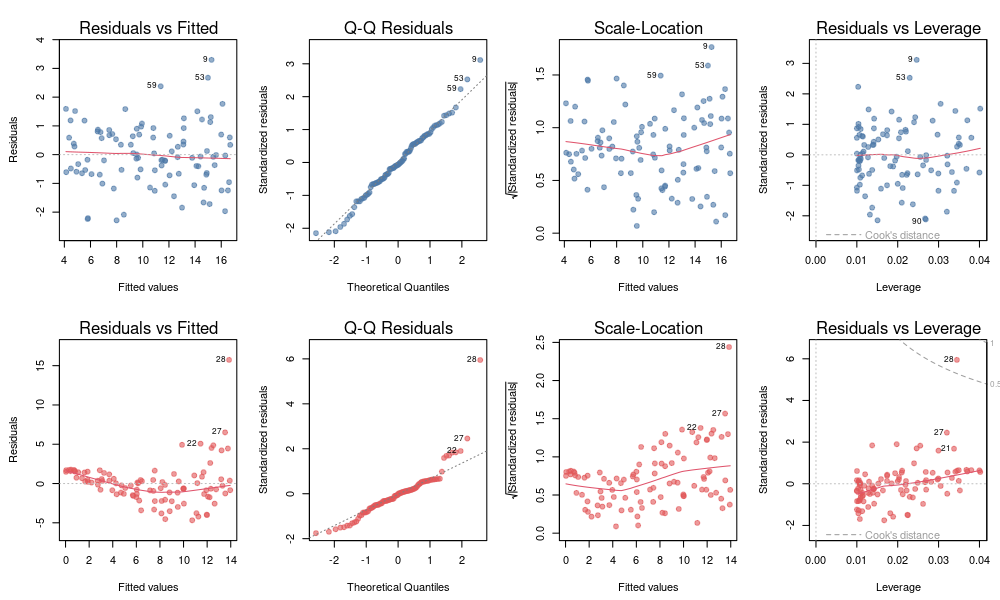

In [6]:
set.seed(16)
x <- runif(100, 1, 10)
y_good <- 2 + 1.5 * x + rnorm(100, 0, 1)                  # assumptions hold
y_bad  <- exp(0.3 + 0.25 * x + rnorm(100, 0, 0.25))       # multiplicative error -> funnel shape

fit_good <- lm(y_good ~ x)
fit_bad  <- lm(y_bad ~ x)

par(mfrow = c(2, 4), mar = c(4.5, 4.5, 3, 1))
plot(fit_good, which = c(1, 2, 3, 5), pch = 19, col = adjustcolor("#4E79A7", 0.6),
     sub.caption = "")
plot(fit_bad, which = c(1, 2, 3, 5), pch = 19, col = adjustcolor("#E15759", 0.6),
     sub.caption = "")

The top row (blue) is a well-behaved model. The bottom row (red) shows the classic **funnel**: residuals spread out as the fitted values grow, and the Scale–Location line slopes upward.

## 7. Fixing a Violation With a Transformation

Heteroscedasticity check: correlation of |residuals| with fitted values (0 = no funnel)


  raw model: 0.38  | log model: 0.165 


Shapiro-Wilk on residuals - raw p = 7.2e-09 | log p = 0.826 


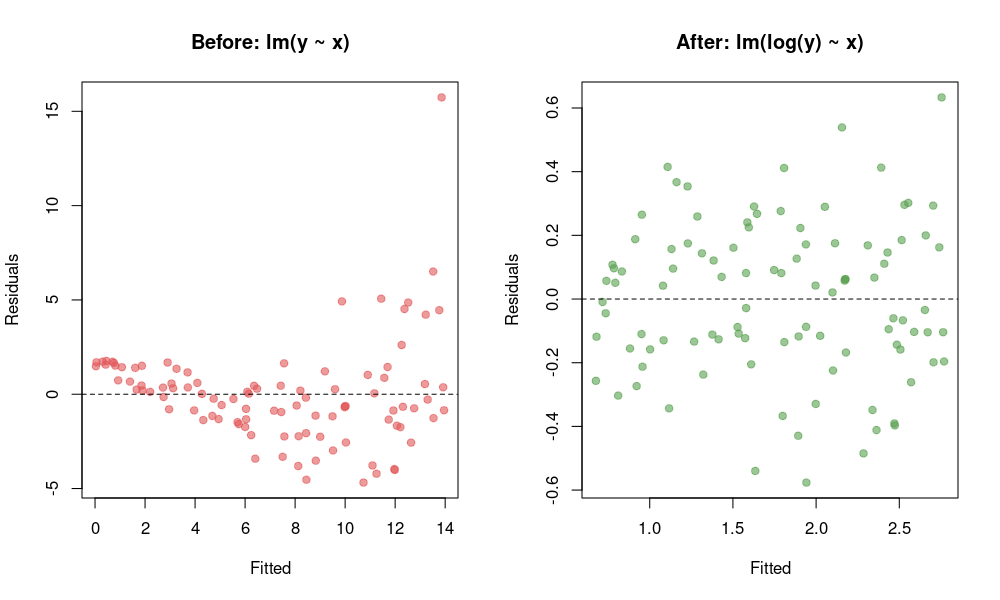

In [7]:
fit_log <- lm(log(y_bad) ~ x)

cat("Heteroscedasticity check: correlation of |residuals| with fitted values (0 = no funnel)\n")
cat("  raw model:", round(cor(abs(resid(fit_bad)), fitted(fit_bad)), 3),
    " | log model:", round(cor(abs(resid(fit_log)), fitted(fit_log)), 3), "\n")
cat("Shapiro-Wilk on residuals - raw p =", signif(shapiro.test(resid(fit_bad))$p.value, 3),
    "| log p =", round(shapiro.test(resid(fit_log))$p.value, 3), "\n")

par(mfrow = c(1, 2))
plot(fitted(fit_bad), resid(fit_bad), pch = 19, col = adjustcolor("#E15759", 0.6),
     main = "Before: lm(y ~ x)", xlab = "Fitted", ylab = "Residuals"); abline(h = 0, lty = 2)
plot(fitted(fit_log), resid(fit_log), pch = 19, col = adjustcolor("#59A14F", 0.6),
     main = "After: lm(log(y) ~ x)", xlab = "Fitted", ylab = "Residuals"); abline(h = 0, lty = 2)

*Insight: Assumption tests depend on the sample size. With 10 points, Shapiro–Wilk almost never rejects even for skewed data; with 10,000 points it rejects tiny, harmless deviations. Use the tests together with the plots, never instead of them.*

## Real-World Use Case or Analogy

- **Independence**: each student's exam paper must be their own work. If students copy from each other, ten papers carry less than ten papers' worth of information.
- **Normality**: test scores forming the classic bell curve.
- **Homogeneity of variances**: plants grown in different soils should vary in height by similar amounts; if one soil gives wildly variable plants, comparing averages alone is unfair.

Checking assumptions is like a **pilot's pre-flight checklist**: most flights would be fine without it, but the checklist catches the rare problem that would make every later reading on the instruments misleading.